# Course: Computer Vision and Pattern Recognition (CVPR)
## Assignment: Assignment 1

**Student Name:** MD Sabbir Hasan  
**Student ID:** 23-51098-1  
**Dataset:** MNISTDigit (Mendeley Data)  
**Framework:** PyTorch  

### Objective
Design and train a custom CNN from scratch to classify handwritten digit images into 10 classes. Compare a plain CNN with the same CNN using Batch Normalization and Dropout, and report results on a separate test set.

In [4]:
!pip -q install torchsummary

# 1. Import Libraries

In [5]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from IPython.display import Markdown, display
%matplotlib inline

from torch.optim import Adam
from torch import optim
from torchsummary import summary
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import seaborn as sns
import matplotlib.ticker as mticker

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f'Device: {device}')
if device == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    torch.backends.cudnn.benchmark = True

torch.manual_seed(10)
np.random.seed(10)

Device: cuda
GPU: Tesla T4


## 2. Load and Explore Dataset

MNISTDigit contains **70,000 grayscale images** of handwritten digits **0–9**, each **28 × 28 pixels**. The Mendeley Data archive (`mnist.npz`) is **11,490,434 bytes** (about 11.5 MB). It contains both the images and labels. The dataset is available under **CC BY 4.0**.

**Source:** Arpit Rai (2023), *MNISTDigit*, Mendeley Data, V1. [Dataset record](https://data.mendeley.com/datasets/k864xjhrw6/1), DOI [10.17632/k864xjhrw6.1](https://doi.org/10.17632/k864xjhrw6.1).

### Data Splitting
- **Training:** 54,000 images (90% of the original 60,000 training images)
- **Validation:** 6,000 images (10% of the original training images)
- **Test:** 10,000 images from the dataset's original test split

A seeded random shuffle splits the original training images into training and validation. The test split remains separate and is used to report final performance.

In [6]:
from hashlib import sha256

data_folder = Path('/content/data')
data_folder.mkdir(parents=True, exist_ok=True)
data_file = data_folder / 'mnist.npz'
data_url = (
    'https://data.mendeley.com/public-files/datasets/k864xjhrw6/'
    'files/781ca35f-e9d6-47db-993a-4b322be75a8f/file_downloaded'
)
mirror_url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
expected_hash = '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'

if not data_file.exists() or sha256(data_file.read_bytes()).hexdigest() != expected_hash:
    temp_file = data_file.with_suffix('.part')
    try:
        urlretrieve(data_url, temp_file)
        if sha256(temp_file.read_bytes()).hexdigest() != expected_hash:
            raise OSError('Unexpected Mendeley download contents.')
        print('Downloaded from Mendeley Data.')
    except OSError:
        urlretrieve(mirror_url, temp_file)
        print('Used the byte-identical mirror of the Mendeley Data archive.')
    if sha256(temp_file.read_bytes()).hexdigest() != expected_hash:
        raise ValueError('The archive does not match the Mendeley Data checksum.')
    temp_file.replace(data_file)

with np.load(data_file) as data:
    all_tr_images = torch.tensor(data['x_train']).unsqueeze(1)
    all_tr_targets = torch.tensor(data['y_train'], dtype=torch.long)
    te_images = torch.tensor(data['x_test']).unsqueeze(1)
    te_targets = torch.tensor(data['y_test'], dtype=torch.long)

val_size = int(0.1 * len(all_tr_images))
rand_ix = torch.randperm(len(all_tr_images))
val_ix = rand_ix[:val_size]
tr_ix = rand_ix[val_size:]

tr_images = all_tr_images[tr_ix]
tr_targets = all_tr_targets[tr_ix]
val_images = all_tr_images[val_ix]
val_targets = all_tr_targets[val_ix]

class_names = [str(i) for i in range(10)]

print('Source archive:', f'{data_file.stat().st_size / 1e6:.2f} MB')
print('Total images:', len(all_tr_images) + len(te_images))
print('Train images:', tr_images.shape)
print('Train labels:', tr_targets.shape)
print('Validation images:', val_images.shape)
print('Validation labels:', val_targets.shape)
print('Test images:', te_images.shape)
print('Test labels:', te_targets.shape)

Used the byte-identical mirror of the Mendeley Data archive.
Source archive: 11.49 MB
Total images: 70000
Train images: torch.Size([54000, 1, 28, 28])
Train labels: torch.Size([54000])
Validation images: torch.Size([6000, 1, 28, 28])
Validation labels: torch.Size([6000])
Test images: torch.Size([10000, 1, 28, 28])
Test labels: torch.Size([10000])


sample image

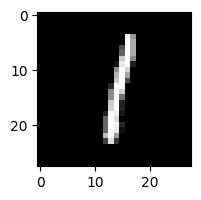

Image (#265): Which is digit '1'


In [7]:
digit = np.random.randint(0, 1000)
a = tr_images[digit, 0]

plt.figure(figsize=(2,2))
plt.imshow(a, cmap="gray")
plt.show()

print(f"Image (#{digit}): Which is digit '{class_names[int(tr_targets[digit])]}'")

show a small grid of images

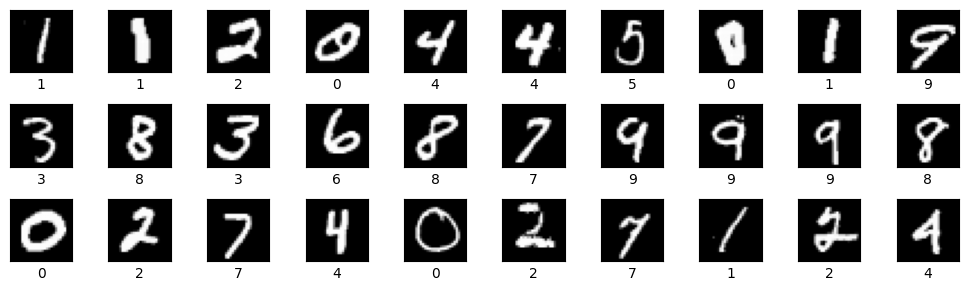

In [8]:
ROWS = 3
COLS = 10
i = 0

plt.figure(figsize=(10,3))
for r in range(ROWS):
    for c in range(COLS):
        plt.subplot(ROWS, COLS, i+1)
        plt.imshow(tr_images[i, 0], cmap="gray")
        plt.xticks([])
        plt.yticks([])
        plt.xlabel(f"{class_names[int(tr_targets[i])]}")
        i += 1

plt.tight_layout()
plt.show()

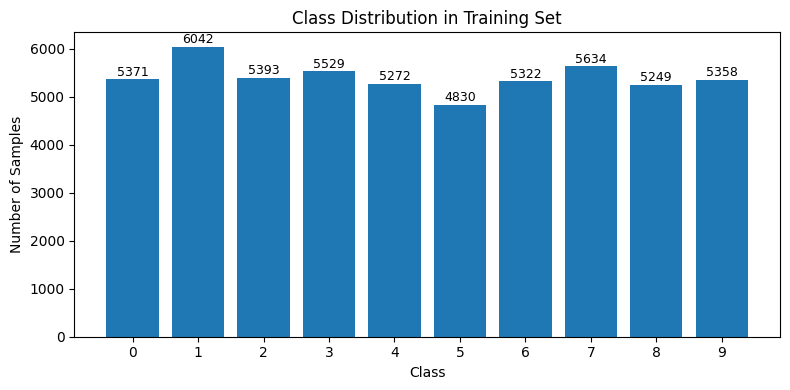

In [9]:
# class distribution in training set

class_counts = np.bincount(tr_targets.cpu().numpy(), minlength=len(class_names))

plt.figure(figsize=(8,4))
bars = plt.bar(class_names, class_counts)
plt.title('Class Distribution in Training Set')
plt.xlabel('Class')
plt.ylabel('Number of Samples')

for bar, count in zip(bars, class_counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             str(count), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Augmentation

### Preprocessing Strategy
- Scale grayscale pixel values to [0, 1].
- Compute the normalization mean and standard deviation using only the 54,000 training images.
- In the training loop, randomly translate each batch by cropping with up to 2 pixels of padding and rotate it by up to 10 degrees. All images in the same batch share the sampled transform. Each new batch draws a new transform.
- Apply only scaling and normalization during validation and testing.

Training batches contain up to 256 images and are shuffled. Validation and test batches contain up to 512 images. Batch-level augmentation cuts down per-image Python work and runs on the same device as the model.

In [10]:
student_id = '23-51098-1'

batch_size_no = 256
eval_batch_size = 512
learning_rate = 1e-3
epoch_number = 10

model_file_plain = f'MNIST_{student_id}_without_BN_Dropout.pth'
model_file_regularized = f'MNIST_{student_id}_with_BN_Dropout.pth'

train_pixels = tr_images.float().div(255)
mean = [train_pixels.mean().item()]
std = [train_pixels.std().item()]
del train_pixels

train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=2),
    transforms.RandomRotation(10)
])
test_transform = transforms.Normalize(mean, std)

print('Training mean:', round(mean[0], 4))
print('Training standard deviation:', round(std[0], 4))

Training mean: 0.1307
Training standard deviation: 0.3081


In [11]:
class MNISTDataset(Dataset):
    def __init__(self, x, y):
        self.x, self.y = x, y

    def __getitem__(self, ix):
        return self.x[ix], self.y[ix]

    def __len__(self):
        return len(self.x)

def get_data():
    train = MNISTDataset(tr_images, tr_targets)
    trn_dl = DataLoader(train, batch_size=batch_size_no, shuffle=True)

    val = MNISTDataset(val_images, val_targets)
    val_dl = DataLoader(val, batch_size=eval_batch_size, shuffle=False)

    test = MNISTDataset(te_images, te_targets)
    te_dl = DataLoader(test, batch_size=eval_batch_size, shuffle=False)

    return trn_dl, val_dl, te_dl

def prepare_batch(x, y, augment=False):
    x = x.to(device).float().div(255)
    if augment:
        x = train_transform(x)
    x = test_transform(x)
    return x, y.to(device)

trn_dl, val_dl, te_dl = get_data()

## 4. Define CNN Architecture

Two variants of the CNN are used in this notebook:

1. **Baseline CNN**  
   A plain convolutional neural network without Batch Normalization or Dropout.

2. **Regularized CNN**  
   A CNN with Batch Normalization and Dropout added to improve optimization stability and reduce overfitting.

### Architecture Summary
The model uses three convolution blocks to progressively learn:

- low-level features such as edges and simple shapes
- mid-level patterns such as digit strokes and local structures
- high-level digit-specific visual representations

Each block uses two 3 × 3 convolutions and one 2 × 2 max pool. The channel counts are 16, 32, and 64, with spatial sizes 28 → 14 → 7 → 3 after pooling. The final 64 × 3 × 3 feature map is flattened and passed to a 128-unit hidden layer.

The classifier then maps these learned features into the 10 output classes.

Define CNN Architecture

In [12]:
def get_model(with_batch_norm=False, with_dropout=False):
    if with_batch_norm == False and with_dropout == False:
        model = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64 * 3 * 3, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        ).to(device)
    else:
        model = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            nn.Flatten(),
            nn.Linear(64 * 3 * 3, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

print('CNN without BatchNorm and Dropout')
plain_model, loss_fn, optimizer = get_model(with_batch_norm=False, with_dropout=False)
summary(plain_model, input_size=(1, 28, 28), device=device);

print('CNN with BatchNorm and Dropout')
regularized_model, loss_fn, optimizer = get_model(with_batch_norm=True, with_dropout=True)
summary(regularized_model, input_size=(1, 28, 28), device=device);

CNN without BatchNorm and Dropout
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 28, 28]             160
              ReLU-2           [-1, 16, 28, 28]               0
            Conv2d-3           [-1, 16, 28, 28]           2,320
              ReLU-4           [-1, 16, 28, 28]               0
         MaxPool2d-5           [-1, 16, 14, 14]               0
            Conv2d-6           [-1, 32, 14, 14]           4,640
              ReLU-7           [-1, 32, 14, 14]               0
            Conv2d-8           [-1, 32, 14, 14]           9,248
              ReLU-9           [-1, 32, 14, 14]               0
        MaxPool2d-10             [-1, 32, 7, 7]               0
           Conv2d-11             [-1, 64, 7, 7]          18,496
             ReLU-12             [-1, 64, 7, 7]               0
           Conv2d-13             [-1, 64, 7, 7]          36,928
     

## 5. Model Design Rationale

Handwritten digits vary in stroke shape, position, and thickness. Three small convolution blocks let the CNN learn edges first, then combinations of strokes, then digit shapes.

### Why compare two models?
The baseline CNN provides a reference point.  
The second CNN adds **Batch Normalization** and **Dropout** so that we can examine whether regularization improves validation and test performance.

### Why Batch Normalization?
Batch Normalization helps stabilize optimization, and can improve convergence.

### Why Dropout?
Dropout reduces overfitting by preventing the network from depending too strongly on individual neurons.

### Why Adam?
Adam is used because it converges quickly and performs well for CNN-based image classification.

### Why validation-based model selection?
The model with the best validation accuracy is saved and used for final testing so that the final evaluation uses the checkpoint chosen on validation data.

## 6. Training Loop with Validation

Both CNN variants are trained using cross-entropy loss and the Adam optimizer.

For each epoch, the notebook records:
- training loss
- training accuracy
- validation loss
- validation accuracy

Each model trains for 10 epochs with Adam at an initial learning rate of 0.001. The scheduler monitors validation loss. Validation accuracy decides which checkpoint to save. Training accuracy is measured in evaluation mode on the unaugmented training images.

In [13]:
def train_batch(x, y, model, opt, loss_fn):
    model.train()
    prediction = model(x)
    batch_loss = loss_fn(prediction, y)
    batch_loss.backward()
    opt.step()
    opt.zero_grad()
    return batch_loss.item()

@torch.no_grad()
def accuracy(x, y, model):
    model.eval()
    prediction = model(x)
    max_values, argmaxes = prediction.max(-1)
    is_correct = argmaxes == y
    return is_correct.cpu().numpy().tolist()

@torch.no_grad()
def validate_batch(x, y, model, loss_fn):
    model.eval()
    prediction = model(x)
    is_correct = prediction.argmax(dim=1) == y
    validation_loss = loss_fn(prediction, y)
    return is_correct.cpu().tolist(), validation_loss.item()

def train_model(model, loss_fn, optimizer, scheduler, trn_dl, val_dl, epoch_number, model_file_name):
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []
    best_val_accuracy = -1

    for epoch in range(epoch_number):
        print(f'--------Epoch Number : {epoch+1}----------')

        train_epoch_losses, train_epoch_accuracies = [], []

        for ix, batch in enumerate(iter(trn_dl)):
            x, y = prepare_batch(*batch, augment=True)
            batch_loss = train_batch(x, y, model, optimizer, loss_fn)
            train_epoch_losses.append(batch_loss)
        train_epoch_loss = np.array(train_epoch_losses).mean()

        for ix, batch in enumerate(iter(trn_dl)):
            x, y = prepare_batch(*batch)
            is_correct = accuracy(x, y, model)
            train_epoch_accuracies.extend(is_correct)
        train_epoch_accuracy = np.mean(train_epoch_accuracies)

        val_epoch_losses, val_epoch_accuracies = [], []
        for ix, batch in enumerate(iter(val_dl)):
            x, y = prepare_batch(*batch)
            val_is_correct, validation_loss = validate_batch(x, y, model, loss_fn)

            val_epoch_accuracies.extend(val_is_correct)
            val_epoch_losses.append(validation_loss)

        val_epoch_accuracy = np.mean(val_epoch_accuracies)
        validation_loss = np.array(val_epoch_losses).mean()

        scheduler.step(validation_loss)
        print(f'Current Learning Rate:{scheduler.get_last_lr()[0]}')
        print(f'Epoch Loss:{train_epoch_loss}')
        print(f'Epoch Accuracy:{train_epoch_accuracy}')
        print(f'Validation Loss:{validation_loss}')
        print(f'Validation Accuracy:{val_epoch_accuracy}')

        train_losses.append(train_epoch_loss)
        train_accuracies.append(train_epoch_accuracy)
        val_losses.append(validation_loss)
        val_accuracies.append(val_epoch_accuracy)

        if val_epoch_accuracy > best_val_accuracy:
            best_val_accuracy = val_epoch_accuracy
            torch.save(model.state_dict(), model_file_name)

    model.load_state_dict(torch.load(model_file_name, map_location=device))
    return model, train_losses, train_accuracies, val_losses, val_accuracies, best_val_accuracy

train model without batch normalization and dropout

In [14]:
torch.manual_seed(10)

plain_model, loss_fn, optimizer = get_model(with_batch_norm=False, with_dropout=False)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    factor=0.5,
    patience=1,
    threshold=0.001,
    min_lr=1e-5,
    threshold_mode='abs'
)

plain_model, plain_train_losses, plain_train_accuracies, plain_val_losses, plain_val_accuracies, plain_best_val_accuracy = train_model(
    plain_model,
    loss_fn,
    optimizer,
    scheduler,
    trn_dl,
    val_dl,
    epoch_number,
    model_file_plain
)

--------Epoch Number : 1----------
Current Learning Rate:0.001
Epoch Loss:0.6768299526936635
Epoch Accuracy:0.9639629629629629
Validation Loss:0.11356953717768192
Validation Accuracy:0.962
--------Epoch Number : 2----------
Current Learning Rate:0.001
Epoch Loss:0.13952298637179403
Epoch Accuracy:0.9776481481481482
Validation Loss:0.07450542474786441
Validation Accuracy:0.9755
--------Epoch Number : 3----------
Current Learning Rate:0.001
Epoch Loss:0.09518132868147856
Epoch Accuracy:0.9842962962962963
Validation Loss:0.05268957155446211
Validation Accuracy:0.9831666666666666
--------Epoch Number : 4----------
Current Learning Rate:0.001
Epoch Loss:0.07456797542341795
Epoch Accuracy:0.9881296296296296
Validation Loss:0.04510207769150535
Validation Accuracy:0.986
--------Epoch Number : 5----------
Current Learning Rate:0.001
Epoch Loss:0.06570644133781653
Epoch Accuracy:0.9893703703703703
Validation Loss:0.0371062564663589
Validation Accuracy:0.988
--------Epoch Number : 6----------
Cur

train model with batch normalization and dropout

In [15]:
torch.manual_seed(10)

regularized_model, loss_fn, optimizer = get_model(with_batch_norm=True, with_dropout=True)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    factor=0.5,
    patience=1,
    threshold=0.001,
    min_lr=1e-5,
    threshold_mode='abs'
)

regularized_model, regularized_train_losses, regularized_train_accuracies, regularized_val_losses, regularized_val_accuracies, regularized_best_val_accuracy = train_model(
    regularized_model,
    loss_fn,
    optimizer,
    scheduler,
    trn_dl,
    val_dl,
    epoch_number,
    model_file_regularized
)

--------Epoch Number : 1----------
Current Learning Rate:0.001
Epoch Loss:0.4283243887373621
Epoch Accuracy:0.9838333333333333
Validation Loss:0.0527552974720796
Validation Accuracy:0.9833333333333333
--------Epoch Number : 2----------
Current Learning Rate:0.001
Epoch Loss:0.09812288485926475
Epoch Accuracy:0.9899259259259259
Validation Loss:0.033049092162400484
Validation Accuracy:0.9898333333333333
--------Epoch Number : 3----------
Current Learning Rate:0.001
Epoch Loss:0.07100339187971223
Epoch Accuracy:0.9925
Validation Loss:0.027662344742566347
Validation Accuracy:0.9918333333333333
--------Epoch Number : 4----------
Current Learning Rate:0.001
Epoch Loss:0.06261398082254764
Epoch Accuracy:0.9923333333333333
Validation Loss:0.0245659997065862
Validation Accuracy:0.9918333333333333
--------Epoch Number : 5----------
Current Learning Rate:0.001
Epoch Loss:0.05200885744297533
Epoch Accuracy:0.9928148148148148
Validation Loss:0.028680030566950638
Validation Accuracy:0.99016666666666

In [16]:
# summary comparison table for baseline and regularized models

@torch.no_grad()
def evaluate_model_on_test(model, te_dl):
    model.eval()
    preds = []
    labels = []

    for x, y in te_dl:
        x, y = prepare_batch(x, y)
        prediction = model(x)
        max_values, argmaxes = prediction.max(-1)
        preds.extend(argmaxes.cpu().numpy().tolist())
        labels.extend(y.cpu().numpy().tolist())

    preds = np.array(preds)
    labels = np.array(labels)

    test_accuracy = np.mean(preds == labels)
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average='weighted',
        zero_division=0
    )

    return test_accuracy, weighted_precision, weighted_recall, weighted_f1

plain_test_accuracy, plain_weighted_precision, plain_weighted_recall, plain_weighted_f1 = evaluate_model_on_test(plain_model, te_dl)
regularized_test_accuracy, regularized_weighted_precision, regularized_weighted_recall, regularized_weighted_f1 = evaluate_model_on_test(regularized_model, te_dl)

print(f'{"Metric":<18} | {"Plain CNN":>12} | {"BN + Dropout CNN":>18}')
print('-' * 55)
print(f'{"Best Val Accuracy":<18} | {plain_best_val_accuracy:>12.4f} | {regularized_best_val_accuracy:>18.4f}')
print(f'{"Test Accuracy":<18} | {plain_test_accuracy:>12.4f} | {regularized_test_accuracy:>18.4f}')
print(f'{"Weighted Precision":<18} | {plain_weighted_precision:>12.4f} | {regularized_weighted_precision:>18.4f}')
print(f'{"Weighted Recall":<18} | {plain_weighted_recall:>12.4f} | {regularized_weighted_recall:>18.4f}')
print(f'{"Weighted F1":<18} | {plain_weighted_f1:>12.4f} | {regularized_weighted_f1:>18.4f}')

Metric             |    Plain CNN |   BN + Dropout CNN
-------------------------------------------------------
Best Val Accuracy  |       0.9915 |             0.9945
Test Accuracy      |       0.9927 |             0.9949
Weighted Precision |       0.9927 |             0.9949
Weighted Recall    |       0.9927 |             0.9949
Weighted F1        |       0.9927 |             0.9949


compare both models and select the better one

Best Validation Accuracy without BatchNorm and Dropout: 0.9915
Best Validation Accuracy with BatchNorm and Dropout: 0.9945
Best model selected for final testing: CNN with BatchNorm and Dropout


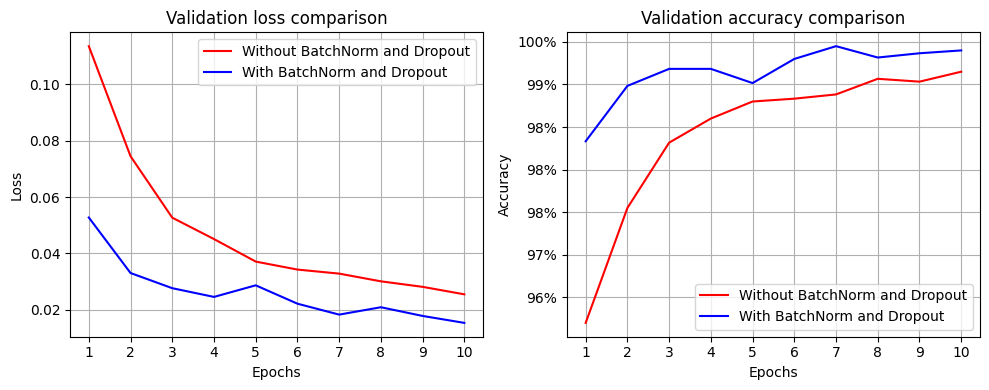

In [17]:


print(f'Best Validation Accuracy without BatchNorm and Dropout: {plain_best_val_accuracy}')
print(f'Best Validation Accuracy with BatchNorm and Dropout: {regularized_best_val_accuracy}')

if regularized_best_val_accuracy >= plain_best_val_accuracy:
    best_model = regularized_model
    best_model_name = 'CNN with BatchNorm and Dropout'
    best_with_regularization = True
    best_train_losses = regularized_train_losses
    best_train_accuracies = regularized_train_accuracies
    best_val_losses = regularized_val_losses
    best_val_accuracies = regularized_val_accuracies
else:
    best_model = plain_model
    best_model_name = 'CNN without BatchNorm and Dropout'
    best_with_regularization = False
    best_train_losses = plain_train_losses
    best_train_accuracies = plain_train_accuracies
    best_val_losses = plain_val_losses
    best_val_accuracies = plain_val_accuracies

print(f'Best model selected for final testing: {best_model_name}')

epochs = np.arange(epoch_number) + 1

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.plot(epochs, plain_val_losses, 'r', label='Without BatchNorm and Dropout')
plt.plot(epochs, regularized_val_losses, 'b', label='With BatchNorm and Dropout')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Validation loss comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')

plt.subplot(122)
plt.plot(epochs, plain_val_accuracies, 'r', label='Without BatchNorm and Dropout')
plt.plot(epochs, regularized_val_accuracies, 'b', label='With BatchNorm and Dropout')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: '{:.0f}%'.format(x*100)))
plt.title('Validation accuracy comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid('off')

plt.tight_layout()
plt.show()

plot training and validation curves of the best model

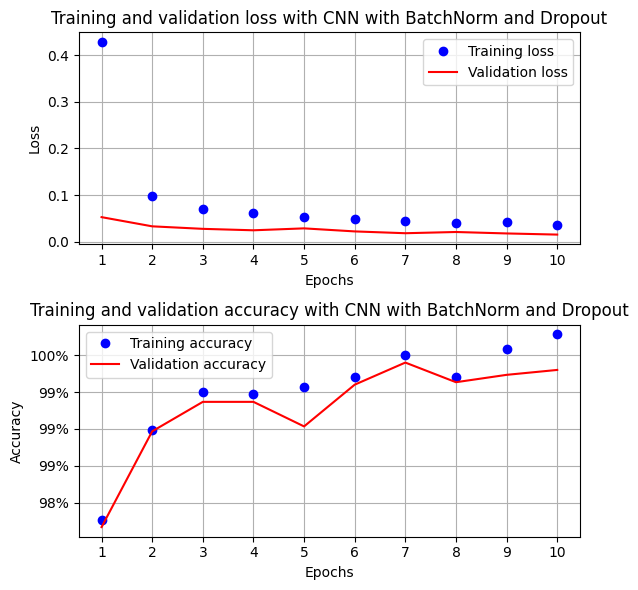

In [18]:


epochs = np.arange(epoch_number) + 1

plt.figure(figsize=(6,6))

plt.subplot(211)
plt.plot(epochs, best_train_losses, 'bo', label='Training loss')
plt.plot(epochs, best_val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title(f'Training and validation loss with {best_model_name}')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')

plt.subplot(212)
plt.plot(epochs, best_train_accuracies, 'bo', label='Training accuracy')
plt.plot(epochs, best_val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: '{:.0f}%'.format(x*100)))
plt.title(f'Training and validation accuracy with {best_model_name}')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid('off')

plt.tight_layout()
plt.show()

## 7. Evaluate Model on Test Set

After selecting the better-performing model using validation accuracy, the model is evaluated on the test set using:

- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix
- Per-class analysis

This gives a more complete view of model quality than accuracy alone.

In [19]:
all_preds = []
all_labels = []

best_model.eval()
with torch.no_grad():
    for ix, batch in enumerate(iter(te_dl)):
        x, y = prepare_batch(*batch)
        prediction = best_model(x)
        max_values, argmaxes = prediction.max(-1)
        all_preds.extend(argmaxes.cpu().numpy().tolist())
        all_labels.extend(y.cpu().numpy().tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_accuracy = np.mean(all_preds == all_labels)

precision, recall, f1, support = precision_recall_fscore_support(
    all_labels,
    all_preds,
    labels=np.arange(10),
    zero_division=0
)

macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    average='macro',
    zero_division=0
)

weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    average='weighted',
    zero_division=0
)

print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'Macro Precision: {macro_precision:.4f}')
print(f'Macro Recall: {macro_recall:.4f}')
print(f'Macro F1 Score: {macro_f1:.4f}')
print(f'Weighted Precision: {weighted_precision:.4f}')
print(f'Weighted Recall: {weighted_recall:.4f}')
print(f'Weighted F1 Score: {weighted_f1:.4f}')

Test Accuracy: 0.9949
Macro Precision: 0.9950
Macro Recall: 0.9948
Macro F1 Score: 0.9949
Weighted Precision: 0.9949
Weighted Recall: 0.9949
Weighted F1 Score: 0.9949


## 8. Visualizations

This section presents the most important visual summaries of the experiment:

- training and validation curves
- model comparison plots
- confusion matrix
- normalized confusion matrix
- per-class F1-score chart
- representative misclassified samples

These visualizations help explain both the model’s strengths and its failure patterns.

Visualizations (Confusion Matrix) and Per-Class Performance

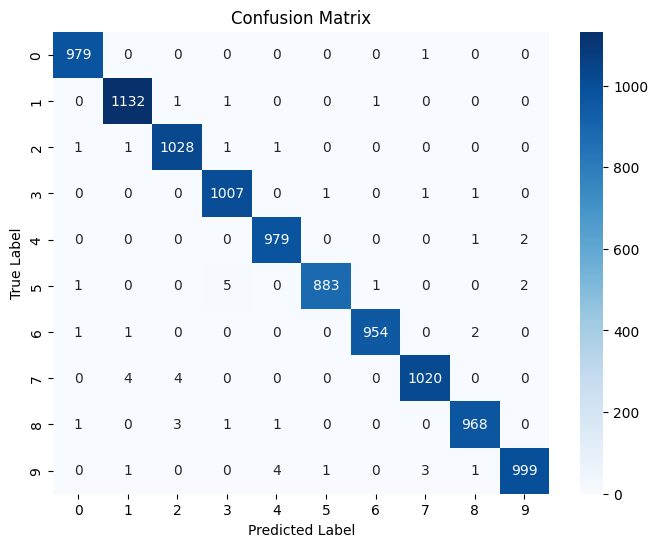

Class: 0 | Precision: 0.9959 | Recall: 0.9990 | F1 Score: 0.9975 | Support: 980 | Class Accuracy: 0.9990
Class: 1 | Precision: 0.9939 | Recall: 0.9974 | F1 Score: 0.9956 | Support: 1135 | Class Accuracy: 0.9974
Class: 2 | Precision: 0.9923 | Recall: 0.9961 | F1 Score: 0.9942 | Support: 1032 | Class Accuracy: 0.9961
Class: 3 | Precision: 0.9921 | Recall: 0.9970 | F1 Score: 0.9946 | Support: 1010 | Class Accuracy: 0.9970
Class: 4 | Precision: 0.9939 | Recall: 0.9969 | F1 Score: 0.9954 | Support: 982 | Class Accuracy: 0.9969
Class: 5 | Precision: 0.9977 | Recall: 0.9899 | F1 Score: 0.9938 | Support: 892 | Class Accuracy: 0.9899
Class: 6 | Precision: 0.9979 | Recall: 0.9958 | F1 Score: 0.9969 | Support: 958 | Class Accuracy: 0.9958
Class: 7 | Precision: 0.9951 | Recall: 0.9922 | F1 Score: 0.9937 | Support: 1028 | Class Accuracy: 0.9922
Class: 8 | Precision: 0.9949 | Recall: 0.9938 | F1 Score: 0.9944 | Support: 974 | Class Accuracy: 0.9938
Class: 9 | Precision: 0.9960 | Recall: 0.9901 | F1 

In [20]:


cm = confusion_matrix(all_labels, all_preds)
class_accuracy = cm.diagonal() / cm.sum(1)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

for ix in range(len(class_names)):
    print(f"Class: {class_names[ix]} | Precision: {precision[ix]:.4f} | Recall: {recall[ix]:.4f} | F1 Score: {f1[ix]:.4f} | Support: {support[ix]} | Class Accuracy: {class_accuracy[ix]:.4f}")

best_class_ix = np.argmax(class_accuracy)
worst_class_ix = np.argmin(class_accuracy)

print()
print(f"Best performing class: {class_names[best_class_ix]} | Accuracy: {class_accuracy[best_class_ix]:.4f} | F1 Score: {f1[best_class_ix]:.4f}")
print(f"Worst performing class: {class_names[worst_class_ix]} | Accuracy: {class_accuracy[worst_class_ix]:.4f} | F1 Score: {f1[worst_class_ix]:.4f}")

normalized confusion matrix

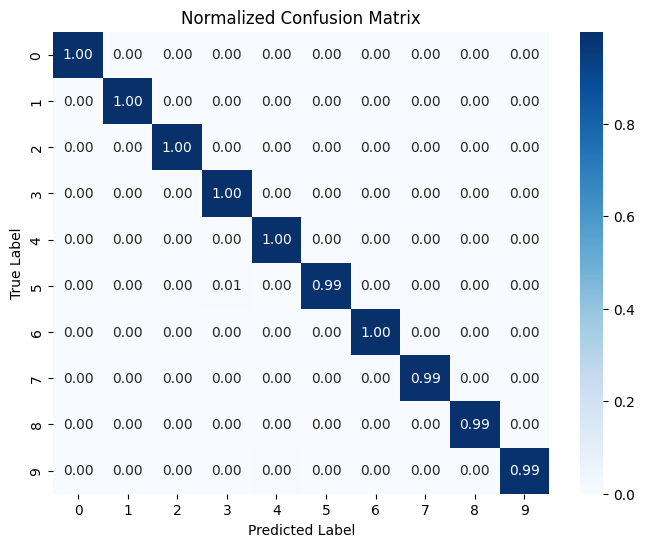

In [21]:
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8,6))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Normalized Confusion Matrix')
plt.show()

per-class F1 score bar chart

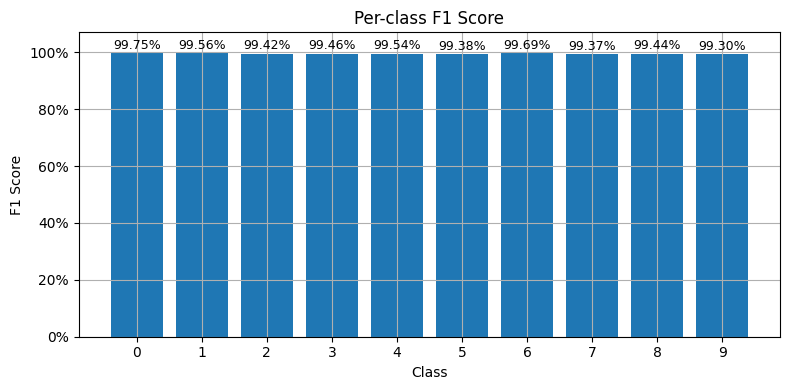

In [22]:
plt.figure(figsize=(8,4))
bars = plt.bar(class_names, f1)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: '{:.0f}%'.format(x*100)))
plt.title('Per-class F1 Score')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.ylim(0, 1.07)

for bar, score in zip(bars, f1):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{score:.2%}', ha='center', va='bottom', fontsize=9)

plt.grid('off')
plt.tight_layout()
plt.show()

additional confusion analysis

In [23]:


cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

top_confusions = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j:
            top_confusions.append((cm_off[i, j], i, j))

top_confusions = sorted(top_confusions, reverse=True)[:5]

print('Top confusing class pairs')
for value, i, j in top_confusions:
    print(f'True class {class_names[i]} predicted as {class_names[j]} : {value} samples')

Top confusing class pairs
True class 5 predicted as 3 : 5 samples
True class 9 predicted as 4 : 4 samples
True class 7 predicted as 2 : 4 samples
True class 7 predicted as 1 : 4 samples
True class 9 predicted as 7 : 3 samples


single prediction example

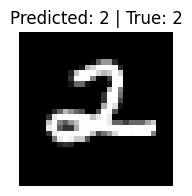

In [24]:
ix = torch.randint(0, len(te_images), ()).item()
img_raw = te_images[ix, 0]
img, _ = prepare_batch(te_images[ix:ix + 1], te_targets[ix:ix + 1])

best_model.eval()
with torch.no_grad():
    prediction = best_model(img)
    pred = prediction.argmax(dim=1).item()

plt.figure(figsize=(2,2))
plt.imshow(img_raw, cmap='gray')
plt.title(f'Predicted: {class_names[pred]} | True: {class_names[int(te_targets[ix])]}')
plt.axis('off')
plt.show()

show some misclassified samples

Total misclassified samples: 51


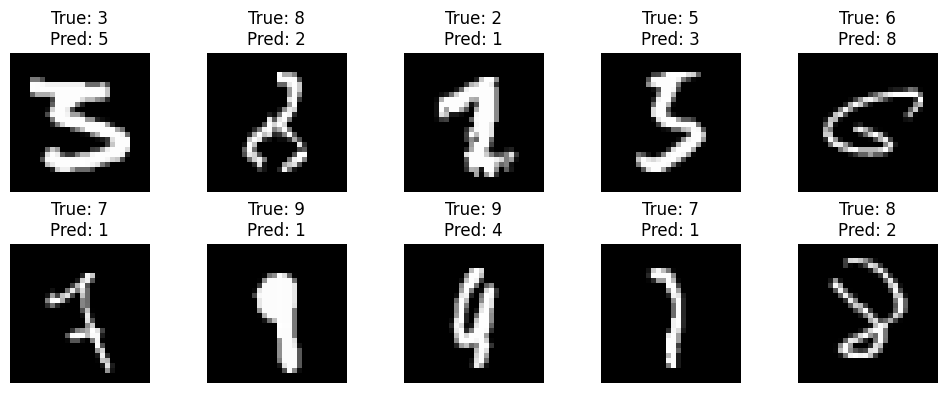

In [25]:
misclassified = np.flatnonzero(all_preds != all_labels)
print(f'Total misclassified samples: {len(misclassified)}')

num_rows = 2
num_cols = 5
num_to_show = min(num_rows * num_cols, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()

for idx in range(num_to_show):
    ix = misclassified[idx]
    img = te_images[ix, 0]
    true = all_labels[ix]
    pred = all_preds[ix]

    axes[idx].imshow(img, cmap='gray', interpolation='nearest')
    axes[idx].set_title(f'True: {class_names[true]}\nPred: {class_names[pred]}')
    axes[idx].axis('off')

for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## 9. Analysis & Discussion of Results

The summary below uses the scores measured during this run.

### 9.1 Effect of Batch Normalization and Dropout
We compare the best validation accuracy, test accuracy, and weighted F1 of both models. The train–validation accuracy gap is measured at each model's best validation epoch. A larger positive gap can indicate overfitting.

### 9.2 Per-class Analysis
The normalized confusion matrix shows recall on its diagonal. Raw counts show which prediction mistakes occur most often. F1 combines precision and recall, so the lowest-recall and lowest-F1 classes can differ.

### 9.3 Class Distribution and Evaluation Metrics
Macro averages give every digit equal weight. Weighted averages give more weight to digits with more test examples.

In [26]:
plain_best_epoch = int(np.argmax(plain_val_accuracies))
regularized_best_epoch = int(np.argmax(regularized_val_accuracies))

plain_gap = plain_train_accuracies[plain_best_epoch] - plain_best_val_accuracy
regularized_gap = regularized_train_accuracies[regularized_best_epoch] - regularized_best_val_accuracy
test_difference = 100 * (regularized_test_accuracy - plain_test_accuracy)
hardest_f1 = int(np.argmin(f1))
top_count, top_true, top_pred = top_confusions[0]
correct_predictions = int((all_preds == all_labels).sum())

display(Markdown(f'''
| Metric | Plain CNN | BN + Dropout CNN |
|---|---:|---:|
| Best epoch | {plain_best_epoch + 1} | {regularized_best_epoch + 1} |
| Best validation accuracy | {plain_best_val_accuracy:.2%} | {regularized_best_val_accuracy:.2%} |
| Test accuracy | {plain_test_accuracy:.2%} | {regularized_test_accuracy:.2%} |
| Weighted F1 | {plain_weighted_f1:.2%} | {regularized_weighted_f1:.2%} |
| Train − validation accuracy at best epoch | {100 * plain_gap:+.2f} pp | {100 * regularized_gap:+.2f} pp |

- **Selected by validation accuracy:** {best_model_name}.
- **Final test result:** {correct_predictions:,} / {len(all_labels):,} correct ({test_accuracy:.2%}).
- **Test difference (regularized − plain):** {test_difference:+.2f} percentage points.
- **Highest recall:** digit {best_class_ix} ({recall[best_class_ix]:.2%}).
- **Lowest recall:** digit {worst_class_ix} ({recall[worst_class_ix]:.2%}).
- **Lowest F1:** digit {hardest_f1} ({f1[hardest_f1]:.2%}).
- **Most common error:** true {top_true}, predicted {top_pred} ({top_count} images).
- **Scope:** this comparison used one split and one run per model. It tests Batch Normalization and Dropout together.
'''))


| Metric | Plain CNN | BN + Dropout CNN |
|---|---:|---:|
| Best epoch | 10 | 7 |
| Best validation accuracy | 99.15% | 99.45% |
| Test accuracy | 99.27% | 99.49% |
| Weighted F1 | 99.27% | 99.49% |
| Train − validation accuracy at best epoch | +0.11 pp | +0.05 pp |

- **Selected by validation accuracy:** CNN with BatchNorm and Dropout.
- **Final test result:** 9,949 / 10,000 correct (99.49%).
- **Test difference (regularized − plain):** +0.22 percentage points.
- **Highest recall:** digit 0 (99.90%).
- **Lowest recall:** digit 5 (98.99%).
- **Lowest F1:** digit 9 (99.30%).
- **Most common error:** true 5, predicted 3 (5 images).
- **Scope:** this comparison used one split and one run per model. It tests Batch Normalization and Dropout together.


## 10. Conclusions & Future Work

### Conclusions
The experiment compares two custom CNNs built from scratch on the same Mendeley Data split. The measured summary above reports the validation-selected model and its test result.

### Future Work
- Repeat the experiment with several seeds and report mean and variation.
- Test Batch Normalization and Dropout separately to measure each contribution.
- Inspect the most confused digit pairs and test small changes to augmentation.
- Evaluate on handwriting from a different source to check how the model generalizes.

# 11. Save trained model weights

In [27]:
# ── Save model weights (.pth) ─────────────────────────────────────────

torch.save(plain_model.state_dict(), 'plain_cnn.pth')
torch.save(regularized_model.state_dict(), 'bnd_cnn.pth')

print('Model weights saved:')
print('  plain_cnn.pth')
print('  bnd_cnn.pth')

# ── Verify they load correctly ────────────────────────────────────────
check_model, _, _ = get_model(with_batch_norm=True, with_dropout=True)
check_model.load_state_dict(torch.load('bnd_cnn.pth', map_location=device))
check_model.eval()

check_preds = []
check_labels = []

with torch.no_grad():
    for x, y in te_dl:
        x, y = prepare_batch(x, y)
        prediction = check_model(x)
        max_values, argmaxes = prediction.max(-1)
        check_preds.extend(argmaxes.cpu().numpy().tolist())
        check_labels.extend(y.cpu().numpy().tolist())

check_preds = np.array(check_preds)
check_labels = np.array(check_labels)
check_test_acc = np.mean(check_preds == check_labels)

print(f'\nReloaded BN+Dropout model — Test accuracy: {check_test_acc:.4f}  ')

Model weights saved:
  plain_cnn.pth
  bnd_cnn.pth

Reloaded BN+Dropout model — Test accuracy: 0.9949  
